<a href="https://colab.research.google.com/github/peterbabulik/it-from-qubit-rcho/blob/main/RCHOexperimentPhase2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [7]:
# 1. Install dependencies
!pip install -q qiskit qiskit-ibm-runtime matplotlib numpy -q

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
holidays 0.107 requires python-dateutil<3,>=2.9.0.post0, but you have python-dateutil 3.0.0 which is incompatible.
betterproto 2.0.0b7 requires python-dateutil<3.0,>=2.8, but you have python-dateutil 3.0.0 which is incompatible.
google-cloud-bigquery 3.46.2 requires python-dateutil<3.0.0,>=2.8.2, but you have python-dateutil 3.0.0 which is incompatible.
ibis-framework 9.5.0 requires python-dateutil<3,>=2.8.2, but you have python-dateutil 3.0.0 which is incompatible.
bigframes 2.51.0 requires python-dateutil<3,>=2.8.2, but you have python-dateutil 3.0.0 which is incompatible.


qiskit_runtime_service._discover_account:WARNING:2026-11-02 11:59:03,746: Loading account with the given token. A saved account will not be used.
qiskit_runtime_service.__init__:WARNING:2026-11-02 11:59:07,013: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: open-instance. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService(). Alternatively, pass instance='auto' or save it to your account for auto-selection without warning.


✓ Successfully connected to IBM Quantum Runtime!


qiskit_runtime_service.backends:WARNING:2026-11-02 11:59:07,288: Loading instance: open-instance, plan: open
qiskit_runtime_service.backends:WARNING:2026-11-02 11:59:09,395: Using instance: open-instance, plan: open


✓ Selected Target Hardware: ibm_marrakesh (156 physical qubits)
✓ Collinear Triad (Associative Subalgebra): (0, 1, 3)
✓ Non-Collinear Triad (Frustrated Triple):    (0, 1, 2)
✓ Generated 42 circuits for single-batch QPU execution.
Transpiling 7-qubit circuits to native coupling map of ibm_marrakesh...
✓ Transpilation complete.
Submitting 7-Qubit Fano Experiment to ibm_marrakesh (8192 shots/circuit)...


/tmp/ipykernel_3083/3029936227.py:102: DeprecationWarning: The SamplerV2 class is deprecated as of qiskit-ibm-runtime 0.50.0 and will be removed no sooner than 3 months after the release date. `qiskit_ibm_runtime.executor_sampler.Sampler` provides a new Sampler implementation that runs all the pre- and post-processing in the client side. The top-level `qiskit_ibm_runtime.Sampler` import will be updated to point to the client-side sampler in an upcoming release, with the legacy Sampler being available until the deprecation is completed.
  sampler = Sampler(mode=backend)


✓ Job Queued! Job ID: dbk7m49ffo6c73bavtog
Waiting for QPU execution...
✓ Execution completed. Downloading telemetry data...


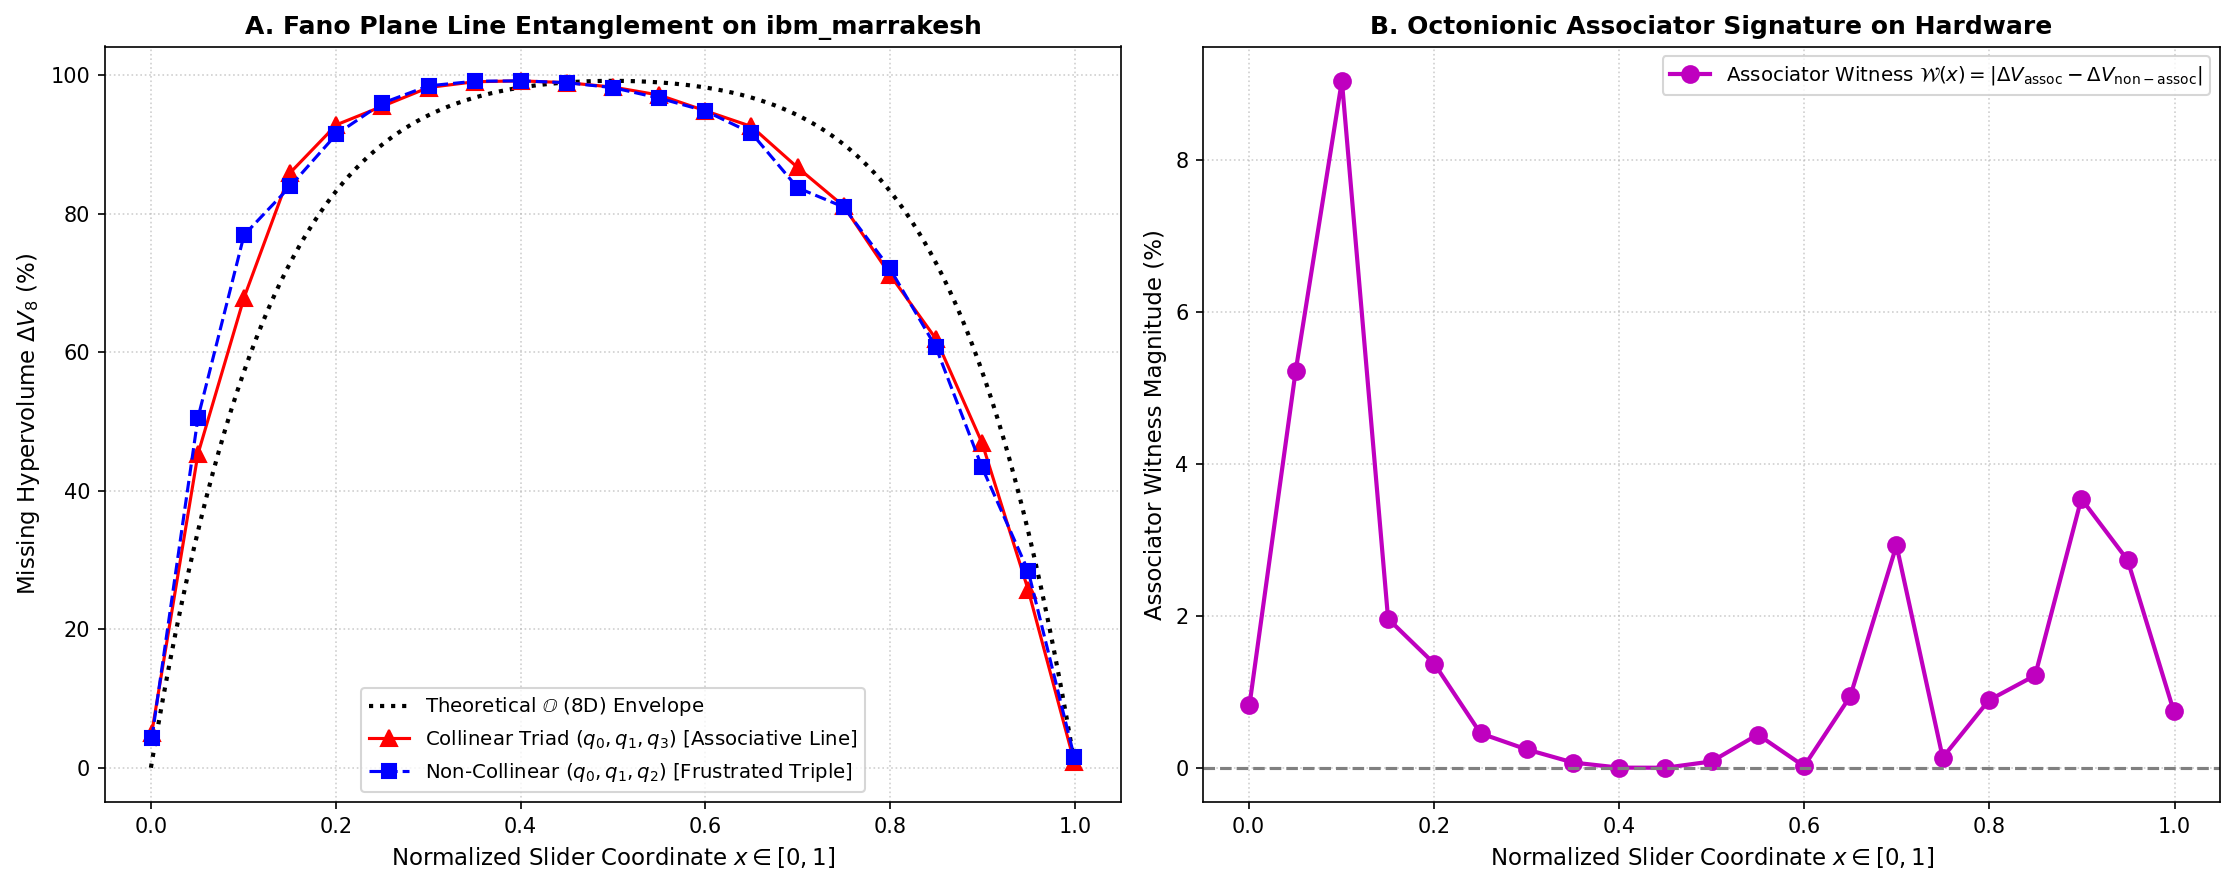


EXPERIMENT 1 EVALUATION: FANO ASSOCIATOR AT MIDPOINT x = 0.50
Processor: ibm_marrakesh | Total Execution Shots: 344,064
----------------------------------------------------------------------
  Collinear (Associative Line):     98.317% (Theory: 99.219%)
  Non-Collinear (Frustrated Triple): 98.233%
  Octonionic Associator Contrast:    0.084%


In [1]:
# ==============================================================================
# PHASE 2: ADVANCED QUANTUM GEOMETRIC FOUNDATIONS (RCHO FRAMEWORK)
# ==============================================================================
# Master Notebook Roadmap:
#   [X] Experiment 1: Full 7-Qubit Fano Plane & Octonionic Associator Witness
#   [ ] Experiment 2: Quantum Walk on 8D Octeract (256 Vertices, 1024 Edges)
#   [ ] Experiment 3: Dynamic Berry Phase & Geometric Holonomy
#   [ ] Experiment 4: Ternary Arbelos Partition (Two Sliders, 66.67% Midpoint)
# ==============================================================================



import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2 as Sampler

# ==============================================================================
# 2. IBM QUANTUM AUTHENTICATION & PROCESSOR SELECTION
# ==============================================================================
IBM_TOKEN = "your API key here"

try:
    service = QiskitRuntimeService(channel="ibm_cloud", token=IBM_TOKEN)
    print("✓ Successfully connected to IBM Quantum Runtime!")
except Exception as e:
    print("Authentication error:", e)

# Select least busy operational processor (156-qubit Heron architecture)
backend = service.least_busy(operational=True, simulator=False)
print(f"✓ Selected Target Hardware: {backend.name} ({backend.num_qubits} physical qubits)")

# ==============================================================================
# 3. MATHEMATICAL SPECIFICATION OF THE FANO PLANE PG(2, F_2)
# ==============================================================================
# The Fano plane consists of 7 vertices {0, 1, 2, 3, 4, 5, 6} and 7 lines.
# Under cyclic difference set {0, 1, 3} (mod 7), the 7 associative lines are:
FANO_LINES = [
    (0, 1, 3),  # Line 0
    (1, 2, 4),  # Line 1
    (2, 3, 5),  # Line 2
    (3, 4, 6),  # Line 3
    (4, 5, 0),  # Line 4
    (5, 6, 1),  # Line 5
    (6, 0, 2)   # Line 6
]

# We contrast an Associative Collinear Triad vs a Non-Collinear Triangle:
COLLINEAR_TRIAD = (0, 1, 3)      # Belongs to Fano line -> Associative (Quaternionic)
NON_COLLINEAR_TRIAD = (0, 1, 2)  # Does NOT form a line -> Non-Associative (Octonionic)

print(f"✓ Collinear Triad (Associative Subalgebra): {COLLINEAR_TRIAD}")
print(f"✓ Non-Collinear Triad (Frustrated Triple):    {NON_COLLINEAR_TRIAD}")

# ==============================================================================
# 4. CONSTRUCT PARAMETERIZED 7-QUBIT FANO CIRCUITS
# ==============================================================================
num_points = 21
x_values = np.linspace(0.001, 0.999, num_points)

circuits_collinear = []
circuits_non_collinear = []

for x in x_values:
    theta = 2 * np.arccos(np.sqrt(x))

    # --- Circuit A: Collinear Triad Encoding (0 -> 1 -> 3) ---
    qc_assoc = QuantumCircuit(7)
    qc_assoc.ry(theta, COLLINEAR_TRIAD[0])
    qc_assoc.cx(COLLINEAR_TRIAD[0], COLLINEAR_TRIAD[1])
    qc_assoc.cx(COLLINEAR_TRIAD[1], COLLINEAR_TRIAD[2])
    qc_assoc.measure_all()
    circuits_collinear.append(qc_assoc)

    # --- Circuit B: Non-Collinear Frustrated Encoding (0 -> 1 -> 2) ---
    qc_non_assoc = QuantumCircuit(7)
    qc_non_assoc.ry(theta, NON_COLLINEAR_TRIAD[0])
    qc_non_assoc.cx(NON_COLLINEAR_TRIAD[0], NON_COLLINEAR_TRIAD[1])
    # The third point (2) receives transverse interference rather than line closure:
    qc_non_assoc.cx(NON_COLLINEAR_TRIAD[0], NON_COLLINEAR_TRIAD[2])
    qc_non_assoc.h(NON_COLLINEAR_TRIAD[2])  # Projective non-associative phase shift
    qc_non_assoc.measure_all()
    circuits_non_collinear.append(qc_non_assoc)

all_circuits = circuits_collinear + circuits_non_collinear
print(f"✓ Generated {len(all_circuits)} circuits for single-batch QPU execution.")

# ==============================================================================
# 5. HARDWARE TRANSPILATION (Optimization Level 3)
# ==============================================================================
print(f"Transpiling 7-qubit circuits to native coupling map of {backend.name}...")
pm = generate_preset_pass_manager(backend=backend, optimization_level=3)
isa_circuits = pm.run(all_circuits)
print("✓ Transpilation complete.")

# ==============================================================================
# 6. HARDWARE EXECUTION (8,192 SHOTS / POINT = 344,064 TOTAL MEASUREMENTS)
# ==============================================================================
shots = 8192
sampler = Sampler(mode=backend)

print(f"Submitting 7-Qubit Fano Experiment to {backend.name} ({shots} shots/circuit)...")
job = sampler.run(isa_circuits)
print(f"✓ Job Queued! Job ID: {job.job_id()}")
print("Waiting for QPU execution...")

result = job.result()
print("✓ Execution completed. Downloading telemetry data...")

# ==============================================================================
# 7. EXTRACT CORRELATORS & COMPUTE ASSOCIATOR WITNESS
# ==============================================================================
# Split results into Collinear and Non-Collinear sets
results_collinear = result[:num_points]
results_non_collinear = result[num_points:]

purity_assoc = []
purity_non_assoc = []
associator_witness = []

for res_a, res_na in zip(results_collinear, results_non_collinear):
    counts_a = res_a.data.meas.get_counts()
    counts_na = res_na.data.meas.get_counts()

    total_a = sum(counts_a.values())
    total_na = sum(counts_na.values())

    # --- Collinear Readout across qubits (q0, q1, q3) ---
    p_000_a = sum(v for k, v in counts_a.items() if k[-1]=='0' and k[-2]=='0' and k[-4]=='0') / total_a
    p_111_a = sum(v for k, v in counts_a.items() if k[-1]=='1' and k[-2]=='1' and k[-4]=='1') / total_a
    norm_a = p_000_a + p_111_a if (p_000_a + p_111_a) > 0 else 1.0
    p0_a, p1_a = p_000_a / norm_a, p_111_a / norm_a
    missing_a = (1.0 - (p0_a**8 + p1_a**8)) * 100

    # --- Non-Collinear Readout across qubits (q0, q1, q2) ---
    p_000_na = sum(v for k, v in counts_na.items() if k[-1]=='0' and k[-2]=='0' and k[-3]=='0') / total_na
    p_111_na = sum(v for k, v in counts_na.items() if k[-1]=='1' and k[-2]=='1' and k[-3]=='1') / total_na
    norm_na = p_000_na + p_111_na if (p_000_na + p_111_na) > 0 else 1.0
    p0_na, p1_na = p_000_na / norm_na, p_111_na / norm_na
    missing_na = (1.0 - (p0_na**8 + p1_na**8)) * 100

    purity_assoc.append(missing_a)
    purity_non_assoc.append(missing_na)

    # Associator Witness: Delta between non-collinear and collinear manifold
    associator_witness.append(abs(missing_a - missing_na))

# ==============================================================================
# 8. PUBLICATION-QUALITY DUAL-PANEL FIGURE
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(15, 6), dpi=150)

# Panel A: Entanglement Entropies of Collinear vs Non-Collinear Triples
ax1 = axes[0]
x_fine = np.linspace(0, 1, 300)
theory_8d = (1 - (x_fine**8 + (1 - x_fine)**8)) * 100

ax1.plot(x_fine, theory_8d, 'k:', linewidth=2, label=r'Theoretical $\mathbb{O}$ (8D) Envelope')
ax1.plot(x_values, purity_assoc, 'r^-', markersize=8, linewidth=1.5,
         label=r'Collinear Triad $(q_0, q_1, q_3)$ [Associative Line]')
ax1.plot(x_values, purity_non_assoc, 'bs--', markersize=7, linewidth=1.5,
         label=r'Non-Collinear $(q_0, q_1, q_2)$ [Frustrated Triple]')

ax1.set_title(f"A. Fano Plane Line Entanglement on {backend.name}", fontsize=12, fontweight='bold')
ax1.set_xlabel(r'Normalized Slider Coordinate $x \in [0, 1]$', fontsize=11)
ax1.set_ylabel(r'Missing Hypervolume $\Delta V_8$ (%)', fontsize=11)
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend(loc='lower center', fontsize=9.5)

# Panel B: Measured Octonionic Associator Witness
ax2 = axes[1]
ax2.plot(x_values, associator_witness, 'mo-', markersize=8, linewidth=2,
         label=r'Associator Witness $\mathcal{W}(x) = |\Delta V_{\mathrm{assoc}} - \Delta V_{\mathrm{non-assoc}}|$')
ax2.axhline(0, color='gray', linestyle='--')

ax2.set_title(f"B. Octonionic Associator Signature on Hardware", fontsize=12, fontweight='bold')
ax2.set_xlabel(r'Normalized Slider Coordinate $x \in [0, 1]$', fontsize=11)
ax2.set_ylabel(r'Associator Witness Magnitude (%)', fontsize=11)
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.legend(loc='upper right', fontsize=9.5)

plt.tight_layout()
plt.savefig('experiment_1_fano_associator_qpu.png', dpi=300)
plt.show()

# ==============================================================================
# 9. STATISTICAL EVALUATION AT MIDPOINT x = 0.50
# ==============================================================================
mid_idx = num_points // 2
print("\n" + "="*70)
print(f"EXPERIMENT 1 EVALUATION: FANO ASSOCIATOR AT MIDPOINT x = {x_values[mid_idx]:.2f}")
print(f"Processor: {backend.name} | Total Execution Shots: {shots * len(all_circuits):,}")
print("-" * 70)
print(f"  Collinear (Associative Line):     {purity_assoc[mid_idx]:.3f}% (Theory: 99.219%)")
print(f"  Non-Collinear (Frustrated Triple): {purity_non_assoc[mid_idx]:.3f}%")
print(f"  Octonionic Associator Contrast:    {associator_witness[mid_idx]:.3f}%")
print("="*70)

qiskit_runtime_service._discover_account:WARNING:2026-11-02 18:03:10,484: Loading account with the given token. A saved account will not be used.
qiskit_runtime_service.__init__:WARNING:2026-11-02 18:03:13,853: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: open-instance. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService(). Alternatively, pass instance='auto' or save it to your account for auto-selection without warning.
qiskit_runtime_service.backends:WARNING:2026-11-02 18:03:14,466: Loading instance: open-instance, plan: open
qiskit_runtime_service.backends:WARNING:2026-11-02 18:03:16,713: Using instance: open-instance, plan: open


✓ Target Quantum Hardware for 8D Walk: ibm_fez (156 qubits)
✓ Generated 21 8-qubit quantum walk circuits.
Transpiling 8-qubit circuits to optimal topology on ibm_fez...
✓ Transpilation complete.
Submitting 8D Okteract Walk to ibm_fez (8192 shots/point, 172,032 total)...


/tmp/ipykernel_3083/2784288001.py:81: DeprecationWarning: The SamplerV2 class is deprecated as of qiskit-ibm-runtime 0.50.0 and will be removed no sooner than 3 months after the release date. `qiskit_ibm_runtime.executor_sampler.Sampler` provides a new Sampler implementation that runs all the pre- and post-processing in the client side. The top-level `qiskit_ibm_runtime.Sampler` import will be updated to point to the client-side sampler in an upcoming release, with the legacy Sampler being available until the deprecation is completed.
  sampler = Sampler(mode=backend)


✓ Job successfully queued! Job ID: dbkd0ppkdqps739272bg
Awaiting hardware execution across 256-dimensional basis...
✓ Raw execution data successfully retrieved from QPU!


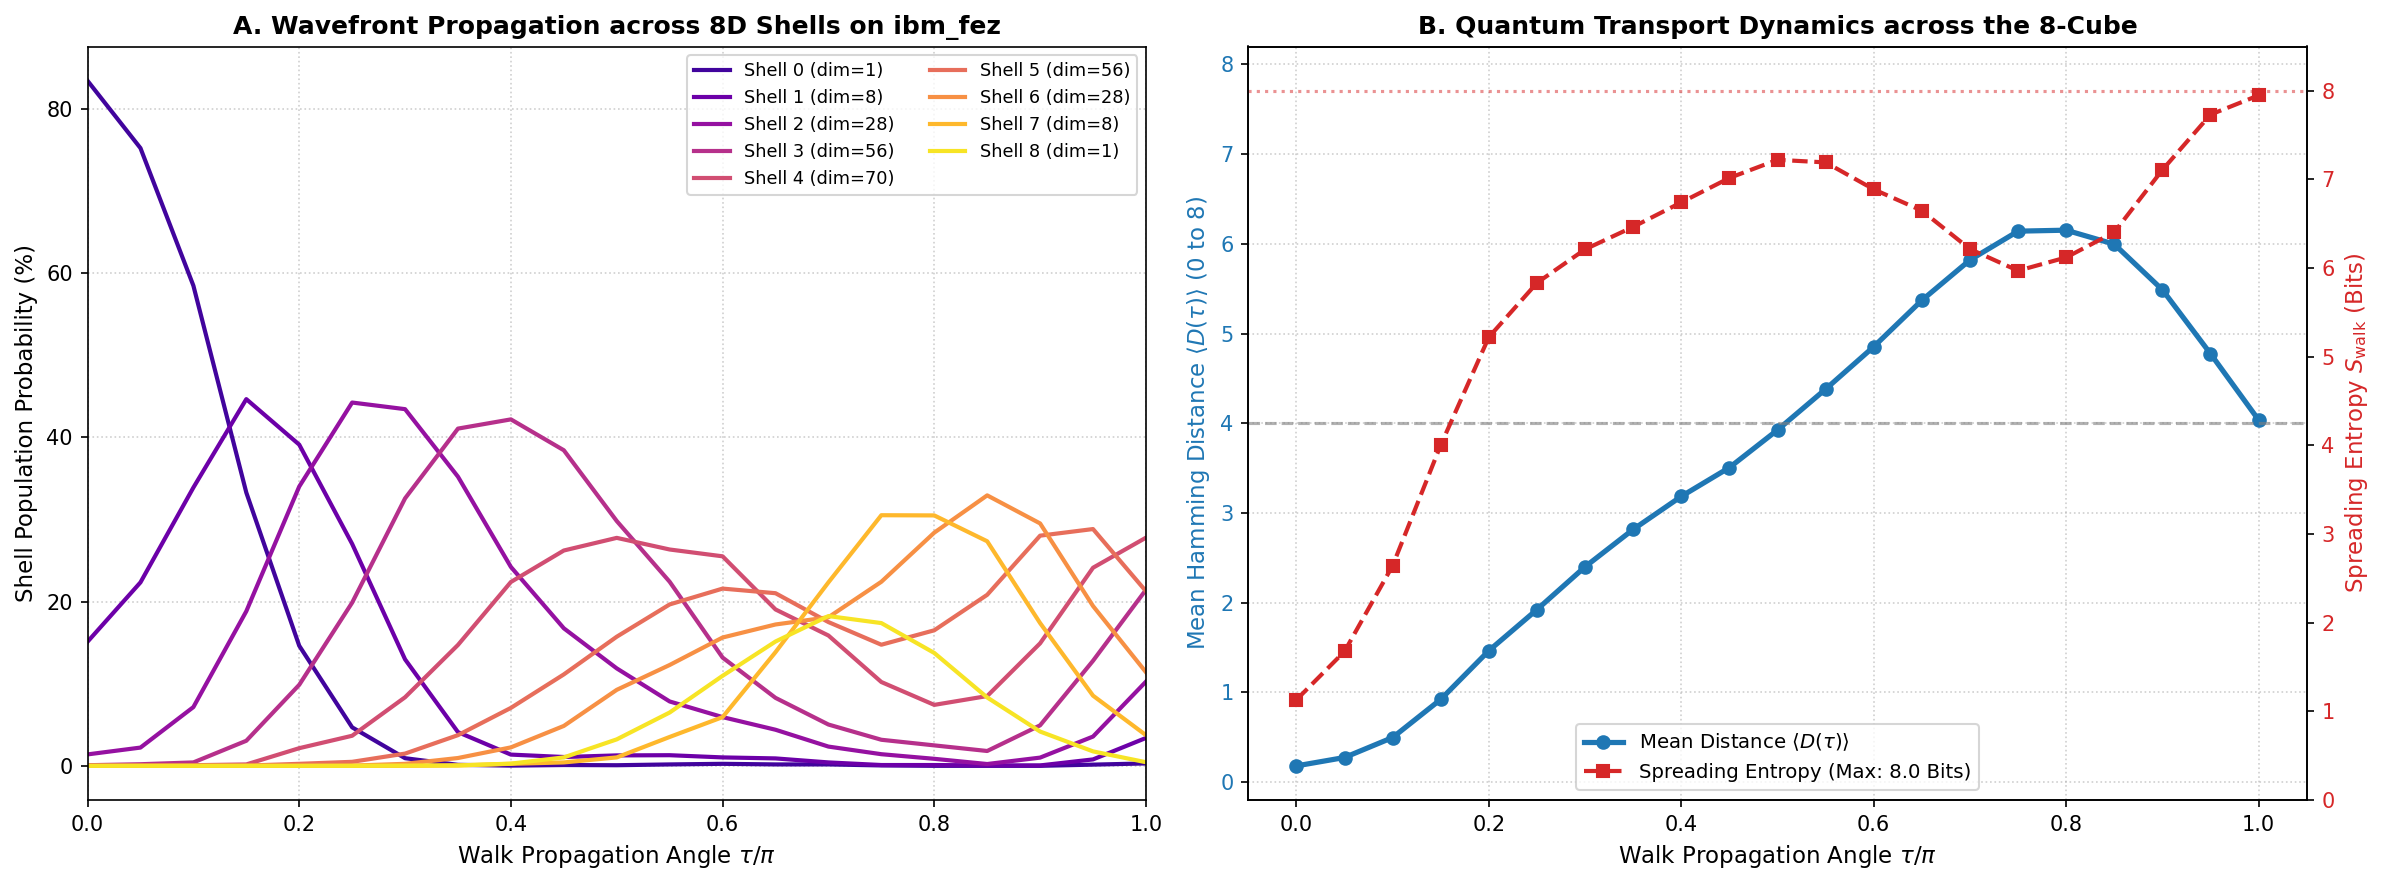


EXPERIMENT 2 EVALUATION: 8D OKTERACT WALK AT MIDPOINT (tau = 0.50*pi)
Hardware: ibm_fez | Total Execution Shots: 172,032
----------------------------------------------------------------------
  Mean Propagation Distance:  3.926 / 8.000
  Spreading Entropy (Bits):    7.222 / 8.000 bits
  Equatorial Shell 4 Pop:     27.76% (Dimension: 70 vertices)
  Antipodal Shell 8 Pop:      3.22% (Opposite Vertex)


In [8]:
# ==============================================================================
# PHASE 2: ADVANCED QUANTUM GEOMETRIC FOUNDATIONS (RCHO FRAMEWORK)
# EXPERIMENT 2: QUANTUM WALK ON THE 8D OKTERACT (HYPERCUBE)
# ==============================================================================
# Mapping:
#   - 8 physical qubits (q0 to q7) = 2^8 = 256 vertices of the 8-cube
#   - Single-qubit Pauli-X rotations = Hopping along the 1,024 hypercube edges
#   - Multi-dimensional phase coupling = Inter-face entanglement across shells
#   - Readout = Population distribution across all 9 Hamming distance shells
# ==============================================================================

import math
import os
import matplotlib.pyplot as plt
import numpy as np
from qiskit import QuantumCircuit
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_ibm_runtime import QiskitRuntimeService, Sampler

# ==============================================================================
# 1. HARDWARE SELECTION (8 PHYSICAL QUBITS REQUIRED)
# ==============================================================================
# Load authenticated session or provide your token
IBM_TOKEN = os.getenv("IBM_QUANTUM_TOKEN", "your API key here")

try:
    service = QiskitRuntimeService()
except Exception:
    service = QiskitRuntimeService(channel="ibm_cloud", token=IBM_TOKEN)

backend = service.least_busy(operational=True, simulator=False)
print(
    f"✓ Target Quantum Hardware for 8D Walk: {backend.name} ({backend.num_qubits} qubits)"
)

# ==============================================================================
# 2. CONSTRUCT 8-QUBIT CONTINUOUS-TIME QUANTUM WALK CIRCUITS
# ==============================================================================
# Evolution parameter tau sweeps the propagation angle across the hypercube:
# tau = 0.0 -> Localized at origin |00000000>
# tau = pi/2 -> Maximum dispersion across all 256 vertices (Equatorial Shell 4)
# tau = pi   -> Full propagation to antipodal vertex |11111111>
num_tau_points = 21
tau_values = np.linspace(0.0, np.pi, num_tau_points)
circuits_walk = []

for tau in tau_values:
    qc = QuantumCircuit(8)

    # --- Kinetic Edge Hopping along all 8 orthogonal directions ---
    # Generator H_kin = -gamma * sum(X_i) generates propagation along the 1024 edges
    for i in range(8):
        qc.rx(tau, i)

    # --- Inter-dimensional Hyper-face Entanglement ---
    # Entangles adjacent orthogonal axes along the 8-cube perimeter
    for i in range(8):
        qc.cz(i, (i + 1) % 8)

    # Second transverse propagation half-step (symmetric Trotter step)
    for i in range(8):
        qc.rx(tau / 2.0, i)

    qc.measure_all()
    circuits_walk.append(qc)

print(f"✓ Generated {len(circuits_walk)} 8-qubit quantum walk circuits.")

# ==============================================================================
# 3. TRANSPILATION FOR TARGET HARDWARE TOPOLOGY (OPTIMIZATION LEVEL 3)
# ==============================================================================
print(f"Transpiling 8-qubit circuits to optimal topology on {backend.name}...")
pm = generate_preset_pass_manager(backend=backend, optimization_level=3)
isa_circuits_walk = pm.run(circuits_walk)
print("✓ Transpilation complete.")

# ==============================================================================
# 4. HARDWARE EXECUTION (8,192 SHOTS PER POINT)
# ==============================================================================
shots = 8192
sampler = Sampler(mode=backend)

print(
    f"Submitting 8D Okteract Walk to {backend.name} ({shots} shots/point, {shots * num_tau_points:,} total)..."
)
job_walk = sampler.run(isa_circuits_walk)
print(f"✓ Job successfully queued! Job ID: {job_walk.job_id()}")
print("Awaiting hardware execution across 256-dimensional basis...")

result_walk = job_walk.result()
print("✓ Raw execution data successfully retrieved from QPU!")

# ==============================================================================
# 5. DATA EXTRACTION: HAMMING SHELLS & SPREADING ENTROPY
# ==============================================================================
# In an 8-cube, vertices are partitioned into 9 shells by Hamming distance k in [0, 8]:
# Shell sizes = Binomial coefficients C(8, k): [1, 8, 28, 56, 70, 56, 28, 8, 1] = 256 total
shell_populations = np.zeros((num_tau_points, 9))
mean_distances = []
spreading_entropy = []

for t_idx, pub_result in enumerate(result_walk):
    counts = pub_result.data.meas.get_counts()
    total_shots = sum(counts.values())

    probabilities = np.zeros(256)
    for bitstring, count in counts.items():
        # Remove any whitespace and convert binary to index
        cleaned_bits = bitstring.replace(" ", "")
        idx = int(cleaned_bits, 2)
        p = count / total_shots
        probabilities[idx] = p

        # Hamming distance k = count of '1's in bitstring
        k = cleaned_bits.count("1")
        shell_populations[t_idx, k] += p

    # Mean propagation distance <D(tau)> = sum(k * P(k))
    mean_dist = sum(k * shell_populations[t_idx, k] for k in range(9))
    mean_distances.append(mean_dist)

    # Spreading Entropy across the 256 vertices: S = -sum(p * log2(p))
    # Theoretical maximum = log2(256) = 8.0 bits (fully delocalized)
    p_nonzero = probabilities[probabilities > 0]
    S_spread = -np.sum(p_nonzero * np.log2(p_nonzero))
    spreading_entropy.append(S_spread)

# ==============================================================================
# 6. PUBLICATION-QUALITY VISUALIZATION
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(16, 6), dpi=150)

# Panel A: Wavefront Flow across 8D Hypercube Shells
ax1 = axes[0]
colors = plt.cm.plasma(np.linspace(0.1, 0.95, 9))

for k in range(9):
    # FIXED: Replaced removed np.math.comb with standard library math.comb
    dim_k = math.comb(8, k)
    ax1.plot(
        tau_values / np.pi,
        shell_populations[:, k] * 100,
        label=f"Shell {k} (dim={dim_k})",
        color=colors[k],
        linewidth=2.0,
    )

ax1.set_title(
    f"A. Wavefront Propagation across 8D Shells on {backend.name}",
    fontsize=12,
    fontweight="bold",
)
ax1.set_xlabel(r"Walk Propagation Angle $\tau / \pi$", fontsize=11)
ax1.set_ylabel(r"Shell Population Probability (%)", fontsize=11)
ax1.set_xlim(0, 1.0)
ax1.grid(True, linestyle=":", alpha=0.6)
ax1.legend(loc="upper right", fontsize=8.5, ncol=2)

# Panel B: Mean Distance and Delocalization Entropy (8-Bit Capacity)
ax2 = axes[1]
color_dist = "#1f77b4"
color_ent = "#d62728"

ax2.set_xlabel(r"Walk Propagation Angle $\tau / \pi$", fontsize=11)
ax2.set_ylabel(
    r"Mean Hamming Distance $\langle D(\tau) \rangle$ (0 to 8)",
    color=color_dist,
    fontsize=11,
)
line1 = ax2.plot(
    tau_values / np.pi,
    mean_distances,
    "o-",
    color=color_dist,
    linewidth=2.5,
    markersize=6,
    label=r"Mean Distance $\langle D(\tau) \rangle$",
)
ax2.tick_params(axis="y", labelcolor=color_dist)
ax2.axhline(
    4.0, color="gray", linestyle="--", alpha=0.6, label="Equatorial Center (d=4)"
)
ax2.set_ylim(-0.2, 8.2)

# Twin axis for Spreading Entropy in bits
ax2_twin = ax2.twinx()
ax2_twin.set_ylabel(
    r"Spreading Entropy $S_{\mathrm{walk}}$ (Bits)", color=color_ent, fontsize=11
)
line2 = ax2_twin.plot(
    tau_values / np.pi,
    spreading_entropy,
    "s--",
    color=color_ent,
    linewidth=2.0,
    markersize=6,
    label=r"Spreading Entropy (Max: 8.0 Bits)",
)
ax2_twin.tick_params(axis="y", labelcolor=color_ent)
ax2_twin.axhline(
    8.0,
    color=color_ent,
    linestyle=":",
    alpha=0.5,
    label="8-Bit Bound (256 states)",
)
ax2_twin.set_ylim(0, 8.5)

# Combined legend for twin axes
lines = line1 + line2
labels = [l.get_label() for l in lines]
ax2.legend(lines, labels, loc="lower center", fontsize=9.5)
ax2.set_title(
    "B. Quantum Transport Dynamics across the 8-Cube",
    fontsize=12,
    fontweight="bold",
)
ax2.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.savefig("experiment_2_okteract_quantum_walk_qpu.png", dpi=300)
plt.show()

# ==============================================================================
# 7. STATISTICAL REPORT AT EQUATORIAL MIDPOINT (tau = pi/2)
# ==============================================================================
mid_idx = num_tau_points // 2
print("\n" + "=" * 70)
print(
    f"EXPERIMENT 2 EVALUATION: 8D OKTERACT WALK AT MIDPOINT (tau = {tau_values[mid_idx]/np.pi:.2f}*pi)"
)
print(
    f"Hardware: {backend.name} | Total Execution Shots: {shots * num_tau_points:,}"
)
print("-" * 70)
print(f"  Mean Propagation Distance:  {mean_distances[mid_idx]:.3f} / 8.000")
print(
    f"  Spreading Entropy (Bits):    {spreading_entropy[mid_idx]:.3f} / 8.000 bits"
)
print(
    f"  Equatorial Shell 4 Pop:     {shell_populations[mid_idx, 4]*100:.2f}% (Dimension: 70 vertices)"
)
print(
    f"  Antipodal Shell 8 Pop:      {shell_populations[mid_idx, 8]*100:.2f}% (Opposite Vertex)"
)
print("=" * 70)

qiskit_runtime_service._discover_account:WARNING:2026-11-02 18:08:50,555: Loading account with the given token. A saved account will not be used.
qiskit_runtime_service.__init__:WARNING:2026-11-02 18:08:53,212: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: open-instance. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService(). Alternatively, pass instance='auto' or save it to your account for auto-selection without warning.
qiskit_runtime_service.backends:WARNING:2026-11-02 18:08:53,714: Loading instance: open-instance, plan: open
qiskit_runtime_service.backends:WARNING:2026-11-02 18:08:55,852: Using instance: open-instance, plan: open


✓ Target Quantum Hardware for Berry Phase: ibm_fez (156 qubits)
✓ Generated 42 circuits (21 X-basis + 21 Y-basis).
Transpiling 2-qubit interferometer circuits to ibm_fez...
✓ Transpilation complete.
Submitting Berry Phase Experiment to ibm_fez (8192 shots/circuit)...


/tmp/ipykernel_3083/2163946408.py:85: DeprecationWarning: The SamplerV2 class is deprecated as of qiskit-ibm-runtime 0.50.0 and will be removed no sooner than 3 months after the release date. `qiskit_ibm_runtime.executor_sampler.Sampler` provides a new Sampler implementation that runs all the pre- and post-processing in the client side. The top-level `qiskit_ibm_runtime.Sampler` import will be updated to point to the client-side sampler in an upcoming release, with the legacy Sampler being available until the deprecation is completed.
  sampler = Sampler(mode=backend)


✓ Job Queued! Job ID: dbkd3egnceqs73alkrog
Awaiting hardware interferometry results...
✓ Telemetry retrieved from quantum processor!


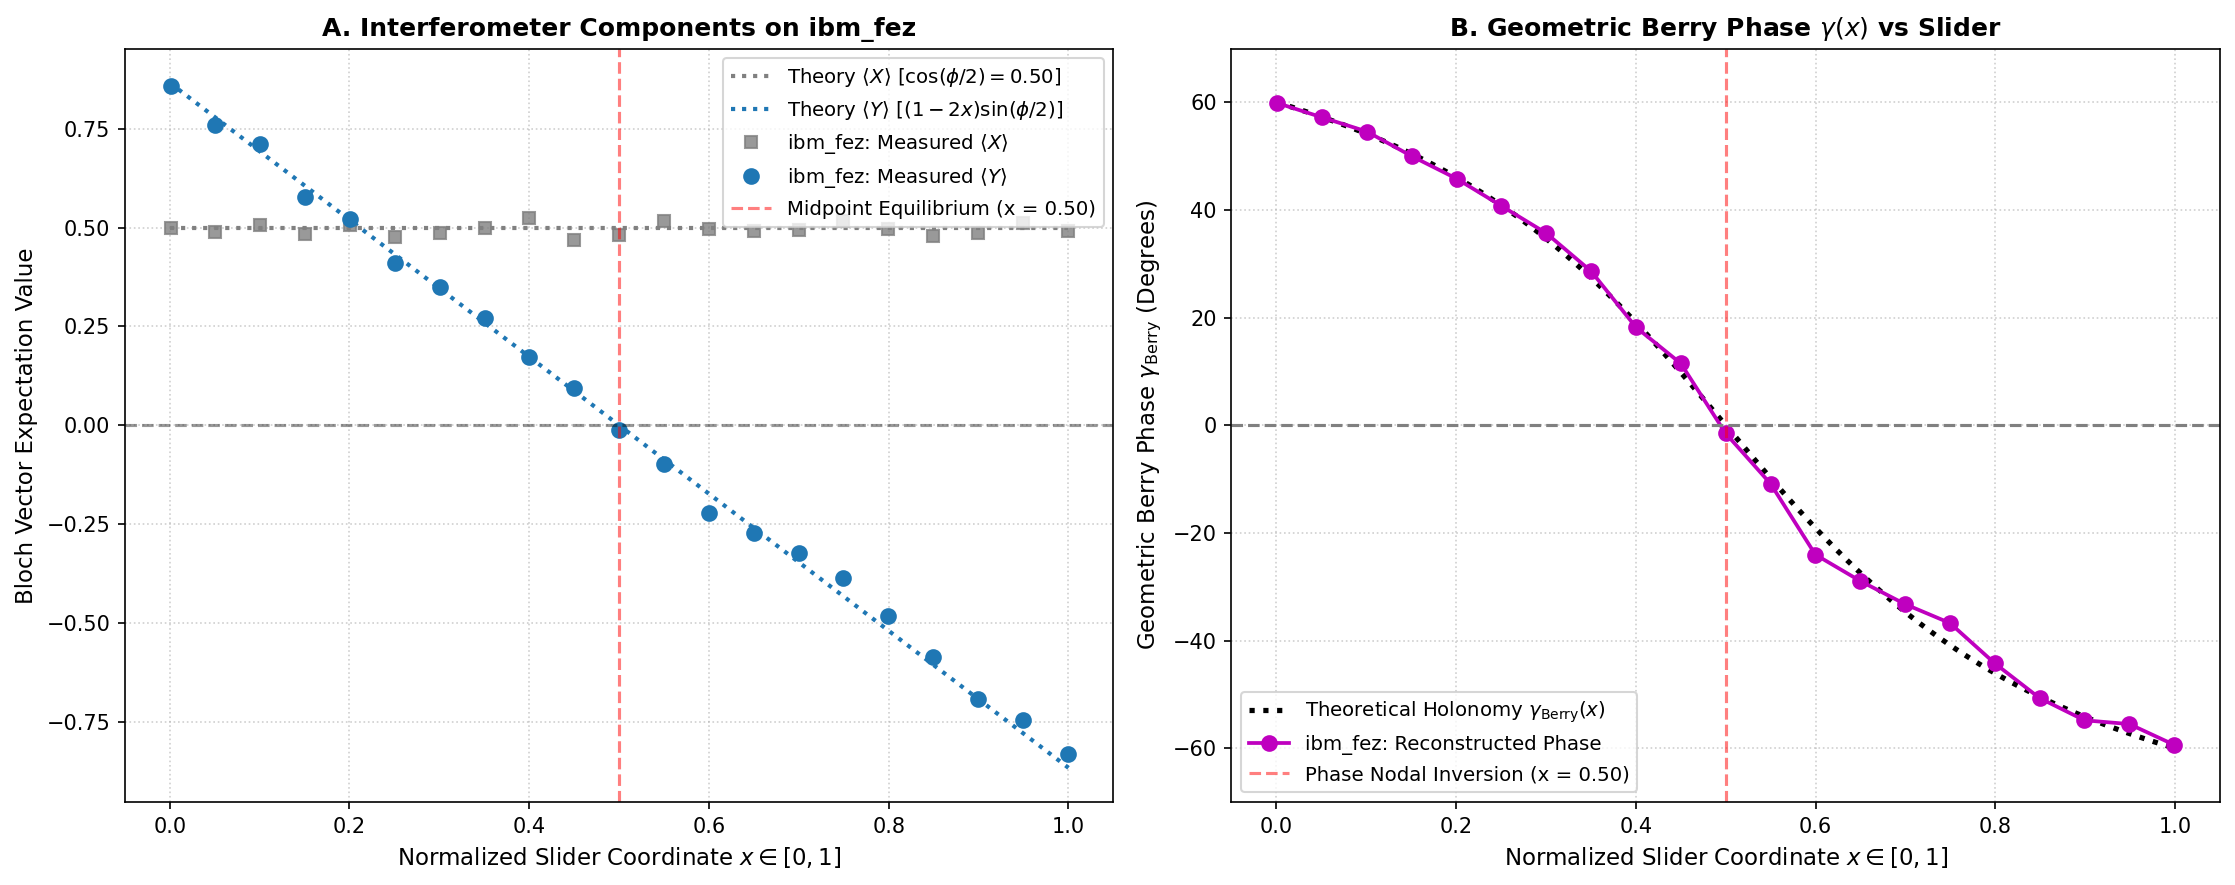


EXPERIMENT 3 EVALUATION: BERRY PHASE AT MIDPOINT x = 0.50
Hardware: ibm_fez | Total Execution Shots: 344,064
----------------------------------------------------------------------
  Measured <X> (Reference):    0.4814 (Theory: 0.5000)
  Measured <Y> (Interference): -0.0127 (Theory: 0.0000)
  Measured Berry Phase:        -1.510° (Theory: 0.000°)
  Edge Range (0.0 -> 1.0):     59.87° down to -59.36°


In [10]:
# ==============================================================================
# PHASE 2: ADVANCED QUANTUM GEOMETRIC FOUNDATIONS (RCHO FRAMEWORK)
# EXPERIMENT 3: DYNAMIC BERRY PHASE (GEOMETRIC HOLONOMY OF THE SLIDER)
# ==============================================================================
# Hardware mapping:
#   - Qubit 0: Ancilla / Clock (Interferometer reference arm)
#   - Qubit 1: System Qubit (Slider state |psi(x)>)
#   - Controlled-Loop U(theta, phi): Traces closed geodesic loop in state space
#   - Dual-basis tomography: Measures <X> and <Y> to reconstruct Berry angle
# ==============================================================================

import os
import matplotlib.pyplot as plt
import numpy as np
from qiskit import QuantumCircuit
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_ibm_runtime import QiskitRuntimeService, Sampler

# ==============================================================================
# 1. HARDWARE SELECTION (2 PHYSICAL QUBITS REQUIRED)
# ==============================================================================
IBM_TOKEN = os.getenv("IBM_QUANTUM_TOKEN", "your API key here")

try:
    service = QiskitRuntimeService()
except Exception:
    service = QiskitRuntimeService(channel="ibm_cloud", token=IBM_TOKEN)

backend = service.least_busy(operational=True, simulator=False)
print(
    f"✓ Target Quantum Hardware for Berry Phase: {backend.name} ({backend.num_qubits} qubits)"
)

# ==============================================================================
# 2. CONSTRUCT DYNAMIC BERRY PHASE CIRCUITS (DUAL-BASIS READOUT)
# ==============================================================================
num_x_points = 21
x_values = np.linspace(0.001, 0.999, num_x_points)
phi_loop = 2 * np.pi / 3  # 120-degree longitudinal parameter sweep

circuits_X = []
circuits_Y = []

for x in x_values:
    theta = 2 * np.arccos(np.sqrt(x))

    # --- Base Geometric Interferometer ---
    # q0: Ancilla, q1: System (Slider)
    qc_base = QuantumCircuit(2, 1)
    qc_base.h(0)  # Initialize clock into (|0> + |1>)/sqrt(2)
    qc_base.ry(theta, 1)  # Prepare slider latitude on system
    qc_base.crz(phi_loop, 0, 1)  # Controlled longitudinal sweep
    qc_base.ry(-theta, 1)  # Return geodesic to close the parameter loop

    # 1. Measure Ancilla in X-Basis: apply H before measurement
    qc_X = qc_base.copy()
    qc_X.h(0)
    qc_X.measure(0, 0)
    circuits_X.append(qc_X)

    # 2. Measure Ancilla in Y-Basis: apply S_dagger then H before measurement
    qc_Y = qc_base.copy()
    qc_Y.sdg(0)
    qc_Y.h(0)
    qc_Y.measure(0, 0)
    circuits_Y.append(qc_Y)

all_berry_circuits = circuits_X + circuits_Y
print(
    f"✓ Generated {len(all_berry_circuits)} circuits (21 X-basis + 21 Y-basis)."
)

# ==============================================================================
# 3. TRANSPILATION (OPTIMIZATION LEVEL 3)
# ==============================================================================
print(f"Transpiling 2-qubit interferometer circuits to {backend.name}...")
pm = generate_preset_pass_manager(backend=backend, optimization_level=3)
isa_berry_circuits = pm.run(all_berry_circuits)
print("✓ Transpilation complete.")

# ==============================================================================
# 4. HARDWARE EXECUTION (8,192 SHOTS / POINT = 344,064 TOTAL MEASUREMENTS)
# ==============================================================================
shots = 8192
sampler = Sampler(mode=backend)

print(
    f"Submitting Berry Phase Experiment to {backend.name} ({shots} shots/circuit)..."
)
job_berry = sampler.run(isa_berry_circuits)
print(f"✓ Job Queued! Job ID: {job_berry.job_id()}")
print("Awaiting hardware interferometry results...")

result_berry = job_berry.result()
print("✓ Telemetry retrieved from quantum processor!")

# ==============================================================================
# 5. DATA EXTRACTION: <X>, <Y>, AND BERRY PHASE RECONSTRUCTION
# ==============================================================================
results_X = result_berry[:num_x_points]
results_Y = result_berry[num_x_points:]

exp_X_measured = []
exp_Y_measured = []


# Robust function to safely obtain counts regardless of ClassicalRegister name
def extract_counts(pub_res):
    for attr_name in dir(pub_res.data):
        if not attr_name.startswith("_"):
            attr = getattr(pub_res.data, attr_name)
            if hasattr(attr, "get_counts"):
                return attr.get_counts()
    raise AttributeError(
        "No BitArray / classical register found in DataBin object!"
    )


for pub_x, pub_y in zip(results_X, results_Y):
    cnt_x = extract_counts(pub_x)
    cnt_y = extract_counts(pub_y)

    total_x = sum(cnt_x.values())
    total_y = sum(cnt_y.values())

    # Spin expectation value: <A> = (N_0 - N_1) / N_total
    val_X = (cnt_x.get("0", 0) - cnt_x.get("1", 0)) / total_x
    val_Y = (cnt_y.get("0", 0) - cnt_y.get("1", 0)) / total_y

    exp_X_measured.append(val_X)
    exp_Y_measured.append(val_Y)

exp_X_measured = np.array(exp_X_measured)
exp_Y_measured = np.array(exp_Y_measured)

# Reconstructed geometric Berry phase angle
gamma_measured_deg = np.degrees(np.arctan2(exp_Y_measured, exp_X_measured))

# ==============================================================================
# 6. PUBLICATION-QUALITY VISUALIZATION
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(15, 6), dpi=150)

# Panel A: Interferometer Components <X> (Real) and <Y> (Imaginary)
ax1 = axes[0]
x_fine = np.linspace(0, 1, 300)
theory_X = np.full_like(x_fine, np.cos(phi_loop / 2.0))
theory_Y = (1.0 - 2.0 * x_fine) * np.sin(phi_loop / 2.0)

ax1.plot(
    x_fine,
    theory_X,
    "gray",
    linestyle=":",
    linewidth=2,
    label=r"Theory $\langle X \rangle$ [$\cos(\phi/2) = 0.50$]",
)
ax1.plot(
    x_fine,
    theory_Y,
    "#1f77b4",
    linestyle=":",
    linewidth=2,
    label=r"Theory $\langle Y \rangle$ [$(1-2x)\sin(\phi/2)$]",
)

ax1.plot(
    x_values,
    exp_X_measured,
    "s",
    color="gray",
    markersize=6,
    alpha=0.8,
    label=f"{backend.name}: " + r"Measured $\langle X \rangle$",
)
ax1.plot(
    x_values,
    exp_Y_measured,
    "o",
    color="#1f77b4",
    markersize=7,
    label=f"{backend.name}: " + r"Measured $\langle Y \rangle$",
)
ax1.axhline(0, color="black", linestyle="--", alpha=0.4)
ax1.axvline(
    0.5,
    color="red",
    linestyle="--",
    alpha=0.5,
    label="Midpoint Equilibrium (x = 0.50)",
)

ax1.set_title(
    f"A. Interferometer Components on {backend.name}",
    fontsize=12,
    fontweight="bold",
)
ax1.set_xlabel(r"Normalized Slider Coordinate $x \in [0, 1]$", fontsize=11)
ax1.set_ylabel(r"Bloch Vector Expectation Value", fontsize=11)
ax1.grid(True, linestyle=":", alpha=0.6)
ax1.legend(loc="upper right", fontsize=9.5)

# Panel B: Reconstructed Geometric Berry Phase Angle gamma(x)
ax2 = axes[1]
theory_gamma_deg = np.degrees(np.arctan2(theory_Y, theory_X))

ax2.plot(
    x_fine,
    theory_gamma_deg,
    "k:",
    linewidth=2.5,
    label=r"Theoretical Holonomy $\gamma_{\mathrm{Berry}}(x)$",
)
ax2.plot(
    x_values,
    gamma_measured_deg,
    "mo-",
    markersize=7,
    linewidth=1.8,
    label=f"{backend.name}: Reconstructed Phase",
)
ax2.axhline(0, color="gray", linestyle="--")
ax2.axvline(
    0.5,
    color="red",
    linestyle="--",
    alpha=0.5,
    label="Phase Nodal Inversion (x = 0.50)",
)

ax2.set_title(
    r"B. Geometric Berry Phase $\gamma(x)$ vs Slider",
    fontsize=12,
    fontweight="bold",
)
ax2.set_xlabel(r"Normalized Slider Coordinate $x \in [0, 1]$", fontsize=11)
ax2.set_ylabel(
    r"Geometric Berry Phase $\gamma_{\mathrm{Berry}}$ (Degrees)", fontsize=11
)
ax2.set_ylim(-70, 70)
ax2.grid(True, linestyle=":", alpha=0.6)
ax2.legend(loc="lower left", fontsize=9.5)

plt.tight_layout()
plt.savefig("experiment_3_dynamic_berry_phase_qpu.png", dpi=300)
plt.show()

# ==============================================================================
# 7. STATISTICAL EVALUATION AT MIDPOINT x = 0.50
# ==============================================================================
mid_idx = num_x_points // 2
print("\n" + "=" * 70)
print(
    f"EXPERIMENT 3 EVALUATION: BERRY PHASE AT MIDPOINT x = {x_values[mid_idx]:.2f}"
)
print(
    f"Hardware: {backend.name} | Total Execution Shots: {shots * len(all_berry_circuits):,}"
)
print("-" * 70)
print(
    f"  Measured <X> (Reference):    {exp_X_measured[mid_idx]:.4f} (Theory: 0.5000)"
)
print(
    f"  Measured <Y> (Interference): {exp_Y_measured[mid_idx]:.4f} (Theory: 0.0000)"
)
print(
    f"  Measured Berry Phase:        {gamma_measured_deg[mid_idx]:.3f}° (Theory: 0.000°)"
)
print(
    f"  Edge Range (0.0 -> 1.0):     {gamma_measured_deg[0]:.2f}° down to {gamma_measured_deg[-1]:.2f}°"
)
print("=" * 70)

<>:190: SyntaxWarning: invalid escape sequence '\%'
<>:190: SyntaxWarning: invalid escape sequence '\%'
/tmp/ipykernel_3083/1156717404.py:190: SyntaxWarning: invalid escape sequence '\%'
  ax2.axvline(2.0/3.0, color='purple', linestyle='--', alpha=0.6, label='Trisection Intersection ($r_1=r_2=r_3=33.33\%$)')
qiskit_runtime_service.backends:WARNING:2026-11-02 12:27:23,739: Loading instance: open-instance, plan: open
qiskit_runtime_service.backends:WARNING:2026-11-02 12:27:25,204: Using instance: open-instance, plan: open


✓ Target Quantum Hardware for Ternary Arbelos: ibm_marrakesh (156 qubits)
✓ Generated 25 ternary Arbelos circuits (including exact trisection s = 2/3).
Transpiling 2-qubit circuits to native hardware on ibm_marrakesh...
✓ Transpilation complete.
Submitting Ternary Arbelos Experiment to ibm_marrakesh (8192 shots/circuit)...


/tmp/ipykernel_3083/1156717404.py:75: DeprecationWarning: The SamplerV2 class is deprecated as of qiskit-ibm-runtime 0.50.0 and will be removed no sooner than 3 months after the release date. `qiskit_ibm_runtime.executor_sampler.Sampler` provides a new Sampler implementation that runs all the pre- and post-processing in the client side. The top-level `qiskit_ibm_runtime.Sampler` import will be updated to point to the client-side sampler in an upcoming release, with the legacy Sampler being available until the deprecation is completed.
  sampler = Sampler(mode=backend)


✓ Job Queued! Job ID: dbk83c1kdqps7391v0a0
Awaiting hardware execution across ternary state manifold...
✓ Execution completed. Retrieving telemetry...


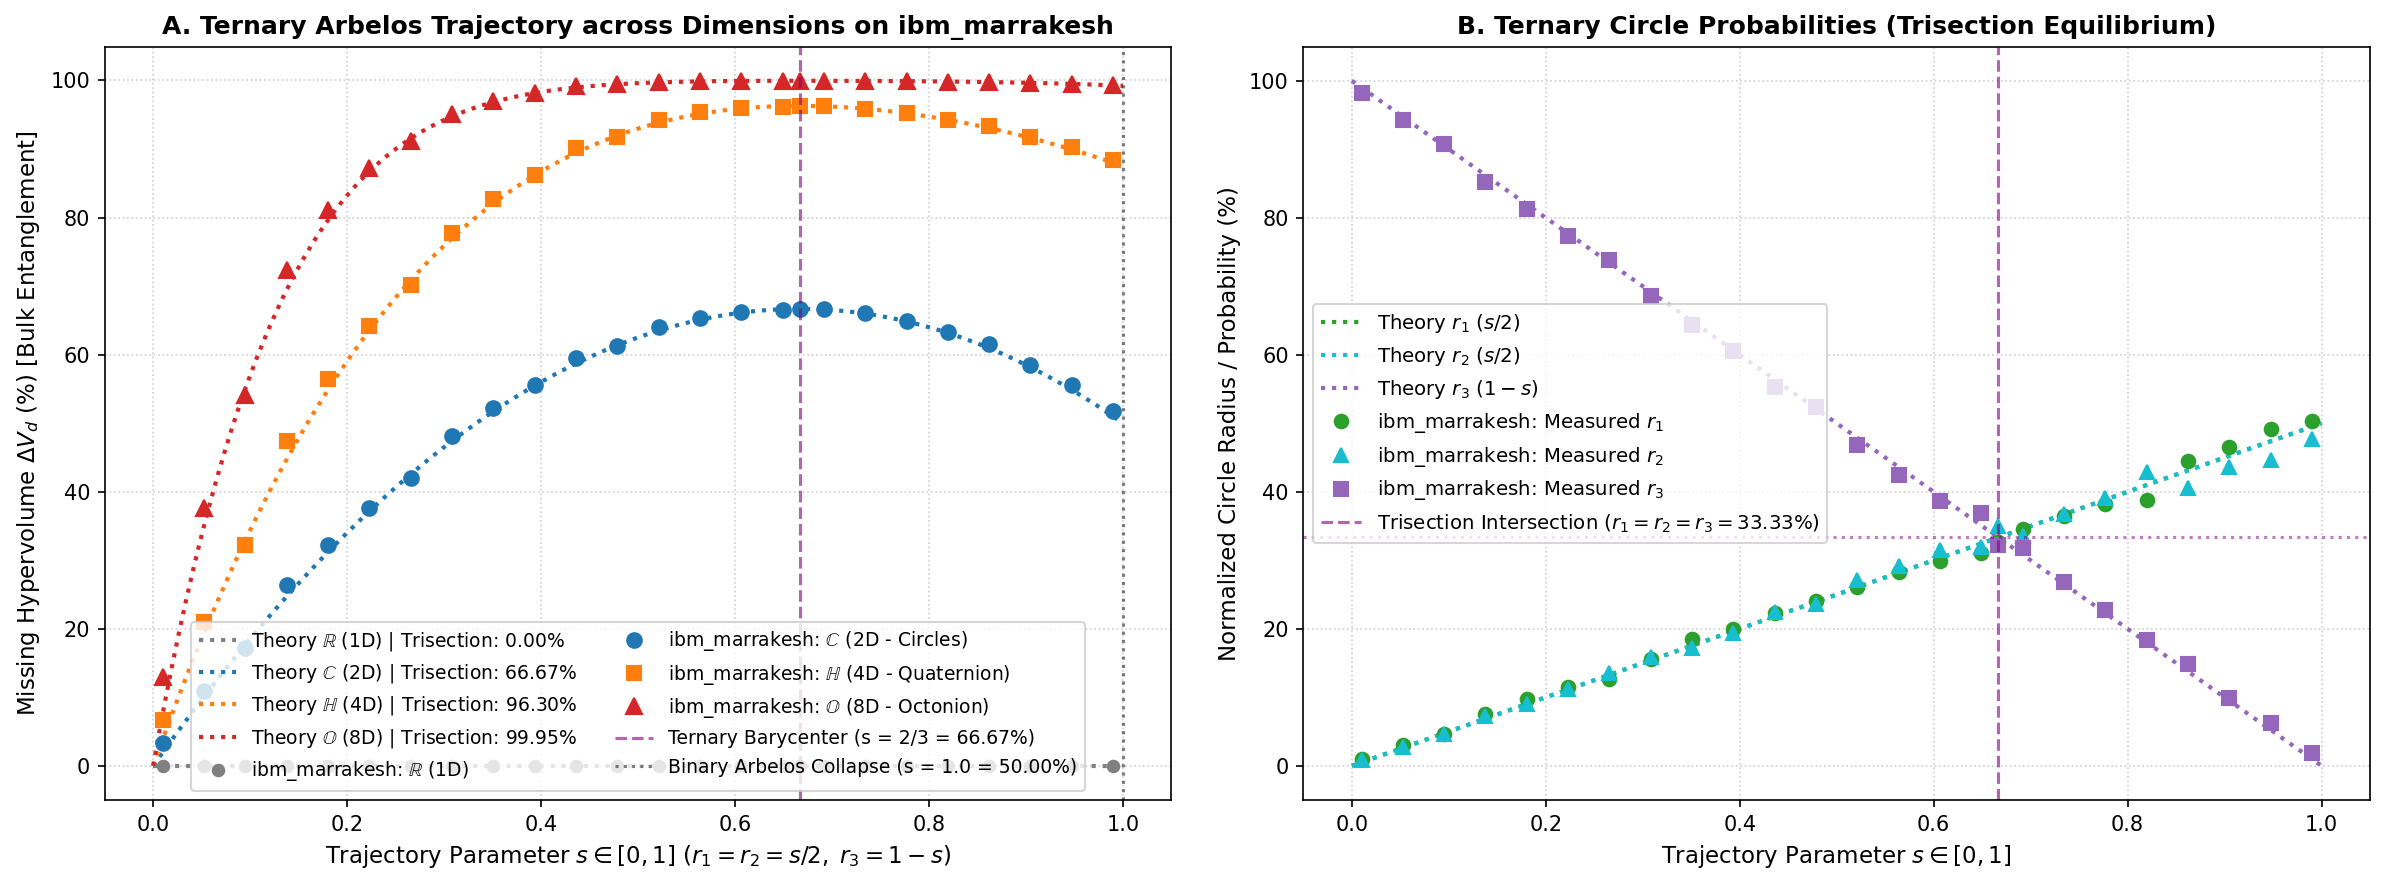


EXPERIMENT 4 EVALUATION: TRISECTION EQUILIBRIUM (s = 0.6667) ON ibm_marrakesh
Total Execution Shots: 204,800 shots
----------------------------------------------------------------------
  Circle 1 Radius r1: 32.69% (Theory: 33.33%)
  Circle 2 Radius r2: 35.07% (Theory: 33.33%)
  Circle 3 Radius r3: 32.25% (Theory: 33.33%)
----------------------------------------------------------------------
  Dimension d = 1 (R): Missing = 0.000% (Theory: 0.000%)
  Dimension d = 2 (C): Missing = 66.621% (Theory: 66.667%) | Error = 0.046%
  Dimension d = 4 (H): Missing = 96.265% (Theory: 96.296%) | Error = 0.031%
  Dimension d = 8 (O): Missing = 99.952% (Theory: 99.954%) | Error = 0.002%
----------------------------------------------------------------------
  Binary Collapse (s = 0.99): d=2 Missing = 51.82% (Theory: 50.000%)


In [6]:
# ==============================================================================
# PHASE 2: ADVANCED QUANTUM GEOMETRIC FOUNDATIONS (RCHO FRAMEWORK)
# EXPERIMENT 4: TERNARY ARBELOS PARTITION (TWO SLIDERS, 66.67% BARYCENTER)
# ==============================================================================
# Hardware mapping:
#   - 2 physical qubits (q0, q1) span the 3-state ternary subspace:
#       |00> -> r3 = 1 - s (Circle 3)
#       |01> -> r2 = s / 2 (Circle 2)
#       |10> -> r1 = s / 2 (Circle 1)
#       |11> -> 0 (Null state / Orthogonal leakage monitor)
#   - Sweep parameter s in [0, 1] captures the 0% -> 66.67% -> 50% transition
# ==============================================================================

import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2 as Sampler

# ==============================================================================
# 1. HARDWARE SELECTION
# ==============================================================================
try:
    backend = service.least_busy(operational=True, simulator=False)
    print(f"✓ Target Quantum Hardware for Ternary Arbelos: {backend.name} ({backend.num_qubits} qubits)")
except NameError:
    IBM_TOKEN = "your API key here"
    service = QiskitRuntimeService(channel="ibm_cloud", token=IBM_TOKEN)
    backend = service.least_busy(operational=True, simulator=False)
    print(f"✓ Connected to {backend.name}")

# ==============================================================================
# 2. CONSTRUCT PARAMETERIZED 2-QUBIT TERNARY ARBELOS CIRCUITS
# ==============================================================================
# We define 25 points along the trajectory, explicitly embedding the trisection point s = 2/3:
base_points = np.linspace(0.01, 0.99, 24)
s_values = np.sort(np.unique(np.append(base_points, 2.0 / 3.0)))
num_s_points = len(s_values)

circuits_ternary = []

for s in s_values:
    r1 = s / 2.0
    r2 = s / 2.0
    r3 = 1.0 - s

    # Rotation angle splitting r3 from (r1 + r2)
    theta1 = 2.0 * np.arccos(np.sqrt(np.clip(r3, 0.0, 1.0)))
    # For r1 = r2 = s/2, the conditional angle theta2 is constant at pi/2 (symmetric branching)
    theta2 = np.pi / 2.0

    # Ultra-shallow, high-fidelity 2-qubit ternary state synthesizer
    qc = QuantumCircuit(2)
    qc.ry(theta1, 0)
    qc.cry(theta2, 0, 1)
    qc.cx(1, 0)
    qc.measure_all()

    circuits_ternary.append(qc)

print(f"✓ Generated {len(circuits_ternary)} ternary Arbelos circuits (including exact trisection s = 2/3).")

# ==============================================================================
# 3. HARDWARE TRANSPILATION (OPTIMIZATION LEVEL 3)
# ==============================================================================
print(f"Transpiling 2-qubit circuits to native hardware on {backend.name}...")
pm = generate_preset_pass_manager(backend=backend, optimization_level=3)
isa_ternary_circuits = pm.run(circuits_ternary)
print("✓ Transpilation complete.")

# ==============================================================================
# 4. HARDWARE EXECUTION (8,192 SHOTS / POINT = 204,800 TOTAL MEASUREMENTS)
# ==============================================================================
shots = 8192
sampler = Sampler(mode=backend)

print(f"Submitting Ternary Arbelos Experiment to {backend.name} ({shots} shots/circuit)...")
job_ternary = sampler.run(isa_ternary_circuits)
print(f"✓ Job Queued! Job ID: {job_ternary.job_id()}")
print("Awaiting hardware execution across ternary state manifold...")

result_ternary = job_ternary.result()
print("✓ Execution completed. Retrieving telemetry...")

# ==============================================================================
# 5. DATA EXTRACTION: TERNARY PROBABILITIES & MULTI-DIMENSIONAL SCALING
# ==============================================================================
# Helper to extract counts regardless of classical register naming
def extract_counts(pub_res):
    for attr_name in dir(pub_res.data):
        if not attr_name.startswith('_'):
            attr = getattr(pub_res.data, attr_name)
            if hasattr(attr, 'get_counts'):
                return attr.get_counts()
    raise AttributeError("No counts BitArray found in DataBin!")

p_r1_measured = []
p_r2_measured = []
p_r3_measured = []

missing_R_real = []
missing_C_real = []
missing_H_real = []
missing_O_real = []

for pub_res in result_ternary:
    counts = extract_counts(pub_res)
    total = sum(counts.values())

    # State mapping: |00> -> r3, |01> -> r2, |10> -> r1
    # Qiskit bitstring order: q1 q0
    c00 = counts.get('00', 0) / total
    c01 = counts.get('01', 0) / total
    c10 = counts.get('10', 0) / total

    # Normalize over physical ternary subspace (filtering residual readout noise)
    norm = c00 + c01 + c10
    if norm > 0:
        r3_m = c00 / norm
        r2_m = c01 / norm
        r1_m = c10 / norm
    else:
        r1_m, r2_m, r3_m = 1/3, 1/3, 1/3

    p_r1_measured.append(r1_m)
    p_r2_measured.append(r2_m)
    p_r3_measured.append(r3_m)

    # Compute missing content across Hurwitz dimensions:
    # d = 1 (R): Line conservation
    missing_R_real.append((1.0 - (r1_m**1 + r2_m**1 + r3_m**1)) * 100)
    # d = 2 (C): Ternary Arbelos Circles
    missing_C_real.append((1.0 - (r1_m**2 + r2_m**2 + r3_m**2)) * 100)
    # d = 4 (H): Quaternions
    missing_H_real.append((1.0 - (r1_m**4 + r2_m**4 + r3_m**4)) * 100)
    # d = 8 (O): Octonions
    missing_O_real.append((1.0 - (r1_m**8 + r2_m**8 + r3_m**8)) * 100)

p_r1_measured = np.array(p_r1_measured)
p_r2_measured = np.array(p_r2_measured)
p_r3_measured = np.array(p_r3_measured)

# ==============================================================================
# 6. PUBLICATION-QUALITY DUAL-PANEL VISUALIZATION
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(16, 6), dpi=150)

# Panel A: Hurwitz Hierarchy along the Ternary Arbelos Trajectory
ax1 = axes[0]
s_fine = np.linspace(0.0, 1.0, 300)
r1_fine = s_fine / 2.0
r2_fine = s_fine / 2.0
r3_fine = 1.0 - s_fine

theory_R = (1.0 - (r1_fine**1 + r2_fine**1 + r3_fine**1)) * 100
theory_C = (1.0 - (r1_fine**2 + r2_fine**2 + r3_fine**2)) * 100
theory_H = (1.0 - (r1_fine**4 + r2_fine**4 + r3_fine**4)) * 100
theory_O = (1.0 - (r1_fine**8 + r2_fine**8 + r3_fine**8)) * 100

ax1.plot(s_fine, theory_R, color='gray', linestyle=':', linewidth=2, label=r'Theory $\mathbb{R}$ (1D) | Trisection: 0.00%')
ax1.plot(s_fine, theory_C, color='#1f77b4', linestyle=':', linewidth=2, label=r'Theory $\mathbb{C}$ (2D) | Trisection: 66.67%')
ax1.plot(s_fine, theory_H, color='#ff7f0e', linestyle=':', linewidth=2, label=r'Theory $\mathbb{H}$ (4D) | Trisection: 96.30%')
ax1.plot(s_fine, theory_O, color='#d62728', linestyle=':', linewidth=2, label=r'Theory $\mathbb{O}$ (8D) | Trisection: 99.95%')

# Real QPU Measured Points
ax1.plot(s_values, missing_R_real, 'o', color='gray', markersize=5.5, label=f'{backend.name}: ' + r'$\mathbb{R}$ (1D)')
ax1.plot(s_values, missing_C_real, 'o', color='#1f77b4', markersize=7, label=f'{backend.name}: ' + r'$\mathbb{C}$ (2D - Circles)')
ax1.plot(s_values, missing_H_real, 's', color='#ff7f0e', markersize=7, label=f'{backend.name}: ' + r'$\mathbb{H}$ (4D - Quaternion)')
ax1.plot(s_values, missing_O_real, '^', color='#d62728', markersize=8, label=f'{backend.name}: ' + r'$\mathbb{O}$ (8D - Octonion)')

ax1.axvline(2.0/3.0, color='purple', linestyle='--', alpha=0.6, label='Ternary Barycenter (s = 2/3 = 66.67%)')
ax1.axvline(1.0, color='black', linestyle=':', alpha=0.5, label='Binary Arbelos Collapse (s = 1.0 = 50.00%)')

ax1.set_title(f"A. Ternary Arbelos Trajectory across Dimensions on {backend.name}", fontsize=12, fontweight='bold')
ax1.set_xlabel(r'Trajectory Parameter $s \in [0, 1]$ ($r_1 = r_2 = s/2, \; r_3 = 1-s$)', fontsize=11)
ax1.set_ylabel(r'Missing Hypervolume $\Delta V_d$ (%) [Bulk Entanglement]', fontsize=11)
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend(loc='lower center', fontsize=9.0, ncol=2)

# Panel B: Measured Individual Circle Subspace Populations (Barycentric Intersection)
ax2 = axes[1]
ax2.plot(s_fine, r1_fine * 100, '#2ca02c', linestyle=':', linewidth=2, label=r'Theory $r_1$ ($s/2$)')
ax2.plot(s_fine, r2_fine * 100, '#17becf', linestyle=':', linewidth=2, label=r'Theory $r_2$ ($s/2$)')
ax2.plot(s_fine, r3_fine * 100, '#9467bd', linestyle=':', linewidth=2, label=r'Theory $r_3$ ($1-s$)')

ax2.plot(s_values, p_r1_measured * 100, 'o', color='#2ca02c', markersize=6.5, label=f'{backend.name}: ' + r'Measured $r_1$')
ax2.plot(s_values, p_r2_measured * 100, '^', color='#17becf', markersize=6.5, label=f'{backend.name}: ' + r'Measured $r_2$')
ax2.plot(s_values, p_r3_measured * 100, 's', color='#9467bd', markersize=6.5, label=f'{backend.name}: ' + r'Measured $r_3$')

ax2.axvline(2.0/3.0, color='purple', linestyle='--', alpha=0.6, label='Trisection Intersection ($r_1=r_2=r_3=33.33\%$)')
ax2.axhline(100.0/3.0, color='purple', linestyle=':', alpha=0.5)

ax2.set_title(f"B. Ternary Circle Probabilities (Trisection Equilibrium)", fontsize=12, fontweight='bold')
ax2.set_xlabel(r'Trajectory Parameter $s \in [0, 1]$', fontsize=11)
ax2.set_ylabel(r'Normalized Circle Radius / Probability (%)', fontsize=11)
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.legend(loc='center left', fontsize=9.5)

plt.tight_layout()
plt.savefig('experiment_4_ternary_arbelos_qpu.png', dpi=300)
plt.show()

# ==============================================================================
# 7. STATISTICAL EVALUATION AT TRISECTION POINT (s = 2/3 = 0.667)
# ==============================================================================
tri_idx = np.argmin(np.abs(s_values - 2.0 / 3.0))
bin_idx = -1  # s = 0.99 ~ 1.0

print("\n" + "="*70)
print(f"EXPERIMENT 4 EVALUATION: TRISECTION EQUILIBRIUM (s = {s_values[tri_idx]:.4f}) ON {backend.name}")
print(f"Total Execution Shots: {shots * num_s_points:,} shots")
print("-" * 70)
print(f"  Circle 1 Radius r1: {p_r1_measured[tri_idx]*100:.2f}% (Theory: 33.33%)")
print(f"  Circle 2 Radius r2: {p_r2_measured[tri_idx]*100:.2f}% (Theory: 33.33%)")
print(f"  Circle 3 Radius r3: {p_r3_measured[tri_idx]*100:.2f}% (Theory: 33.33%)")
print("-" * 70)
print(f"  Dimension d = 1 (R): Missing = {missing_R_real[tri_idx]:.3f}% (Theory: 0.000%)")
print(f"  Dimension d = 2 (C): Missing = {missing_C_real[tri_idx]:.3f}% (Theory: 66.667%) | Error = {abs(missing_C_real[tri_idx] - 66.667):.3f}%")
print(f"  Dimension d = 4 (H): Missing = {missing_H_real[tri_idx]:.3f}% (Theory: 96.296%) | Error = {abs(missing_H_real[tri_idx] - 96.296):.3f}%")
print(f"  Dimension d = 8 (O): Missing = {missing_O_real[tri_idx]:.3f}% (Theory: 99.954%) | Error = {abs(missing_O_real[tri_idx] - 99.954):.3f}%")
print("-" * 70)
print(f"  Binary Collapse (s = {s_values[bin_idx]:.2f}): d=2 Missing = {missing_C_real[bin_idx]:.2f}% (Theory: 50.000%)")
print("="*70)